In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import torch 
import torch.nn as nn 
from torch.utils.data import DataLoader, TensorDataset
import time, copy

In [2]:
DATA_DIR = r"D:\TECH405\DNASequences\DataSets"
FIG_DIR  = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


In [3]:
# 1. Load the dataset into a pandas DataFrame
file_path = os.path.join(DATA_DIR, "all_combined_dna.csv")
all_combined_dna = pd.read_csv(file_path)

# 2. View the dataset
print(all_combined_dna.info())

<class 'pandas.DataFrame'>
RangeIndex: 37812 entries, 0 to 37811
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   sequence  37812 non-null  str  
 1   class     37812 non-null  str  
 2   gene      37812 non-null  str  
dtypes: str(3)
memory usage: 50.2 MB
None


In [4]:
display(all_combined_dna.groupby('class').size())

class
Homo sapiens       18113
Pan troglodytes    19699
dtype: int64

In [5]:
import torch.nn.functional as F
 
from sklearn.metrics import (confusion_matrix, classification_report, f1_score,
                              accuracy_score, precision_recall_fscore_support)
from sklearn.dummy import DummyClassifier

In [6]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
 
 
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
 
 
set_seed()
sns.set_theme(style="whitegrid")

Device: cpu


# Loading trained file from EDA

In [7]:

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_balanced.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "val_final.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_final.csv"))
 
classes = sorted(train_df["class"].unique())
label_map = {c: i for i, c in enumerate(classes)}
num_classes = len(classes)
 
y_train = train_df["class"].map(label_map).values
y_val = val_df["class"].map(label_map).values
y_test = test_df["class"].map(label_map).values
 
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)
 


In [8]:
print(label_map)

{'Homo sapiens': 0, 'Pan troglodytes': 1}


# One-hot encoding (same as EDA)

In [9]:
MAX_LEN = 200
 
 
def encode_sequence(seq, max_len=None):
    """One-hot encode a DNA sequence. 'N' (or any non-ACGT char) becomes
    an all-zero vector instead of being mapped to a real base."""
    mapping = {'A': [1, 0, 0, 0],
               'C': [0, 1, 0, 0],
               'G': [0, 0, 1, 0],
               'T': [0, 0, 0, 1]}
    encoded = [mapping.get(base, [0, 0, 0, 0]) for base in str(seq).upper()]
    arr = np.array(encoded, dtype=np.float32)
    if max_len is not None:
        if len(arr) < max_len:
            pad = np.zeros((max_len - len(arr), 4), dtype=np.float32)
            arr = np.vstack([arr, pad])
        else:
            arr = arr[:max_len]
    return arr

In [10]:
def build_onehot(seqs, max_len=MAX_LEN):
    return np.stack([encode_sequence(s, max_len) for s in seqs]).astype(np.float32)
 
 
X_train = torch.tensor(build_onehot(train_df["sequence"]))
X_val = torch.tensor(build_onehot(val_df["sequence"]))
X_test = torch.tensor(build_onehot(test_df["sequence"]))
print("Shapes after One hot coding :", X_train.shape,
       X_val.shape,
         X_test.shape)

Shapes after One hot coding : torch.Size([39960, 200, 4]) torch.Size([5557, 200, 4]) torch.Size([5559, 200, 4])


In [11]:
class DNACNN(nn.Module):
    def __init__(self, num_classes, conv_channels=(32, 64, 128),
                 kernel_sizes=(7, 5, 3), dropout=0.3, fc_hidden=128):
        super().__init__()
        layers, in_ch = [], 4
        for out_ch, k in zip(conv_channels, kernel_sizes):
            layers += [nn.Conv1d(in_ch, out_ch, kernel_size=k, padding=k // 2),
                       nn.BatchNorm1d(out_ch),
                       nn.ReLU(),
                       nn.MaxPool1d(2)]
            in_ch = out_ch
        self.conv = nn.Sequential(*layers)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(in_ch, fc_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_hidden, num_classes)
        )
 
    def forward(self, x):
        # x arrives as (batch, seq_len, 4) -> Conv1d wants (batch, channels, seq_len)
        x = x.transpose(1, 2)
        x = self.conv(x)
        x = self.pool(x).squeeze(-1)
        return self.fc(x)



In [12]:

@torch.no_grad()
def predict_logits(model, X, batch_size=256):
    model.eval()
    out = [model(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)]
    return torch.cat(out)
 
 
BASELINE = dict(
    conv_channels=(32, 64, 128), kernel_sizes=(7, 5, 3),
    dropout=0.3, fc_hidden=128,
    optimizer="adam", lr=1e-3, weight_decay=0.0,
    batch_size=64, epochs=40, patience=8,
    class_weight=False,
)
 

In [13]:
def train_model(overrides=None, verbose=False):
    cfg = {**BASELINE, **(overrides or {})}
    set_seed(SEED)
 
    model = DNACNN(num_classes, cfg["conv_channels"], cfg["kernel_sizes"],
                    cfg["dropout"], cfg["fc_hidden"]).to(DEVICE)
 
    weight = None
    if cfg["class_weight"]:
        counts = np.bincount(y_train, minlength=num_classes)
        weight = torch.tensor(counts.sum() / (num_classes * counts), dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weight)
 
    if cfg["optimizer"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"])
    else:
        raise ValueError("optimizer must be 'adam' or 'sgd'")
 
    gen = torch.Generator(); gen.manual_seed(SEED)
    loader = DataLoader(TensorDataset(X_train, y_train_t), batch_size=cfg["batch_size"],
                         shuffle=True, generator=gen, drop_last=True)
 
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
    best = dict(f1=-1, state=None, epoch=0)
    bad, t0 = 0, time.time()
 
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        run_loss, correct, n = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
 
        v_logits = predict_logits(model, X_val)
        v_pred = v_logits.argmax(1).numpy()
        v_loss = F.cross_entropy(v_logits, y_val_t).item()
        v_acc = accuracy_score(y_val, v_pred)
        v_f1 = f1_score(y_val, v_pred, average="macro", zero_division=0)
 
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(v_loss); hist["val_acc"].append(v_acc); hist["val_f1"].append(v_f1)
 
        if verbose:
            print(f"Epoch {epoch:02d} | train loss {run_loss/n:.4f} acc {correct/n:.3f} | "
                  f"val loss {v_loss:.4f} acc {v_acc:.3f} macro-F1 {v_f1:.3f}")
 
        if v_f1 > best["f1"]:
            best.update(f1=v_f1, state=copy.deepcopy(model.state_dict()), epoch=epoch); bad = 0
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
 
    model.load_state_dict(best["state"])
    b = best["epoch"] - 1
    return dict(cfg=cfg, model=model, history=hist, best_epoch=best["epoch"], epochs_run=len(hist["val_f1"]),
                val_f1=hist["val_f1"][b], val_acc=hist["val_acc"][b], train_acc=hist["train_acc"][b],
                seconds=time.time() - t0)

In [14]:

def plot_history(res, title="Training curves", save_as=None):
    h = res["history"]; ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="val")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="train"); ax[1].plot(ep, h["val_acc"], label="val")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    ax[2].plot(ep, h["val_f1"], color="tab:green"); ax[2].axvline(res["best_epoch"], ls="--", color="grey")
    ax[2].set_title("Validation macro-F1 (dashed = best epoch)"); ax[2].set_xlabel("epoch")
    fig.suptitle(title); plt.tight_layout()
    if save_as:
        plt.savefig(os.path.join(FIG_DIR, save_as), dpi=150)
    plt.show()
 
 

# Hyperparameter:

Epoch 01 | train loss 0.6974 acc 0.501 | val loss 0.6939 acc 0.478 macro-F1 0.324
Epoch 02 | train loss 0.6933 acc 0.498 | val loss 0.6945 acc 0.478 macro-F1 0.323
Epoch 03 | train loss 0.6932 acc 0.497 | val loss 0.6932 acc 0.478 macro-F1 0.324
Epoch 04 | train loss 0.6932 acc 0.502 | val loss 0.6934 acc 0.478 macro-F1 0.323
Epoch 05 | train loss 0.6932 acc 0.501 | val loss 0.6935 acc 0.478 macro-F1 0.323
Epoch 06 | train loss 0.6935 acc 0.497 | val loss 0.6936 acc 0.478 macro-F1 0.323
Epoch 07 | train loss 0.6932 acc 0.499 | val loss 0.6930 acc 0.522 macro-F1 0.343
Epoch 08 | train loss 0.6932 acc 0.503 | val loss 0.6935 acc 0.478 macro-F1 0.323
Epoch 09 | train loss 0.6932 acc 0.500 | val loss 0.6930 acc 0.522 macro-F1 0.343
Epoch 10 | train loss 0.6932 acc 0.496 | val loss 0.6932 acc 0.478 macro-F1 0.323
Epoch 11 | train loss 0.6934 acc 0.502 | val loss 0.6930 acc 0.522 macro-F1 0.343
Epoch 12 | train loss 0.6932 acc 0.498 | val loss 0.6933 acc 0.478 macro-F1 0.323
Epoch 13 | train

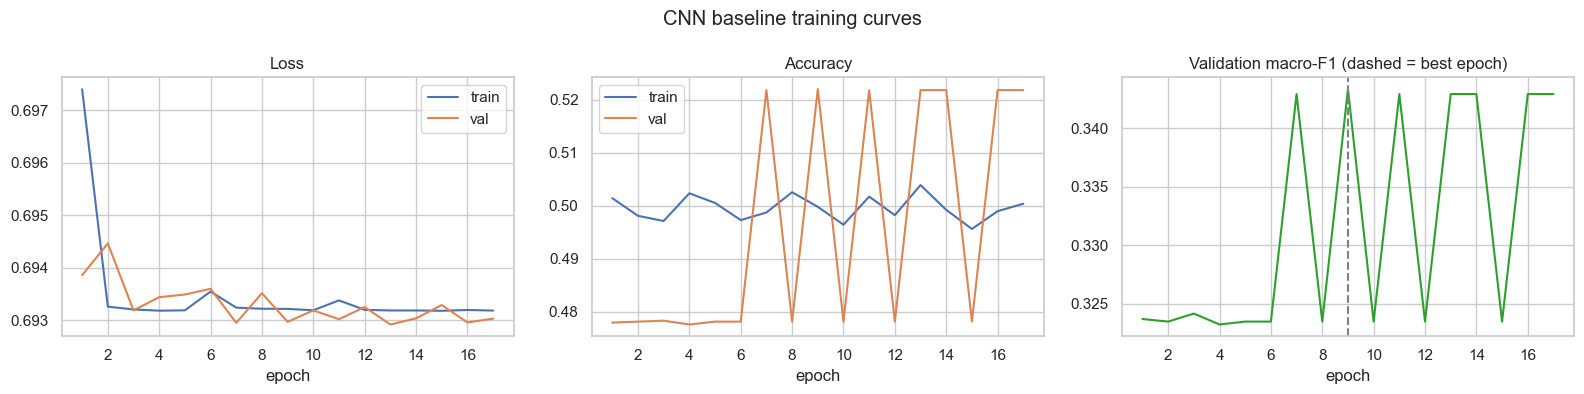

Running baseline               -> val macro-F1 0.343 | val acc 0.522 | best epoch 9/17 | 179s
Running lr=0.01                -> val macro-F1 0.343 | val acc 0.522 | best epoch 4/12 | 107s
Running lr=0.0001              -> val macro-F1 0.505 | val acc 0.505 | best epoch 1/9 | 79s
Running channels=(16, 32)      -> val macro-F1 0.505 | val acc 0.509 | best epoch 3/11 | 41s
Running channels=(32, 64, 128, 256) -> val macro-F1 0.351 | val acc 0.522 | best epoch 1/9 | 126s
Running dropout=0.0            -> val macro-F1 0.505 | val acc 0.512 | best epoch 17/25 | 221s
Running dropout=0.5            -> val macro-F1 0.343 | val acc 0.522 | best epoch 7/15 | 138s
Running batch=32               -> val macro-F1 0.343 | val acc 0.522 | best epoch 14/22 | 264s
Running batch=128              -> val macro-F1 0.504 | val acc 0.505 | best epoch 16/24 | 191s
Running class_weight=True      -> val macro-F1 0.500 | val acc 0.500 | best epoch 4/12 | 127s
Running kernels=(3, 3, 3)      -> val macro-F1 0.474 | v

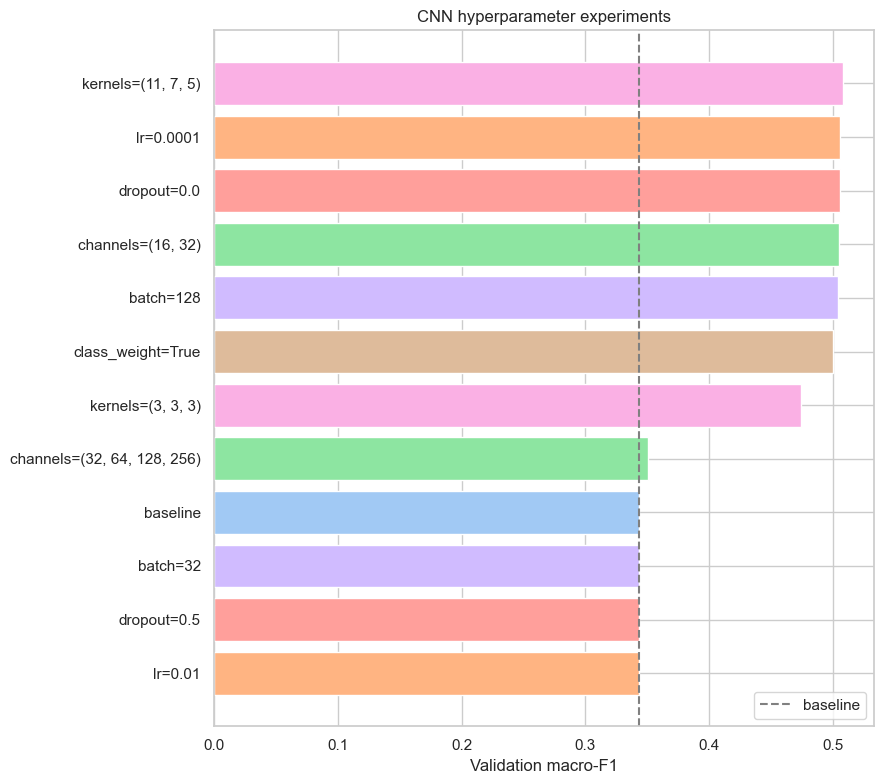

In [15]:
baseline = train_model({}, verbose=True)
print(f"\nBest epoch {baseline['best_epoch']} | val macro-F1 {baseline['val_f1']:.3f} | val acc {baseline['val_acc']:.3f}")
plot_history(baseline, "CNN baseline training curves", "cnn_baseline_curves.png")
  
experiments = [("baseline", "baseline", {})]
 
for lr in [1e-2, 1e-4]:
    experiments.append(("learning_rate", f"lr={lr}", {"lr": lr}))
for ch in [(16, 32), (32, 64, 128, 256)]:
    experiments.append(("architecture", f"channels={ch}",
                         {"conv_channels": ch, "kernel_sizes": tuple([7, 5, 3, 3][:len(ch)])}))
for dp in [0.0, 0.5]:
    experiments.append(("dropout", f"dropout={dp}", {"dropout": dp}))
for bs in [32, 128]:
    experiments.append(("batch_size", f"batch={bs}", {"batch_size": bs}))
experiments.append(("loss", "class_weight=True", {"class_weight": True}))
for k in [(3, 3, 3), (11, 7, 5)]:
    experiments.append(("kernel_size", f"kernels={k}", {"kernel_sizes": k}))
 
results = {}
for group, name, ov in experiments:
    print(f"Running {name:<22}", end=" ")
    results[name] = train_model(ov)
    r = results[name]
    print(f"-> val macro-F1 {r['val_f1']:.3f} | val acc {r['val_acc']:.3f} | "
          f"best epoch {r['best_epoch']}/{r['epochs_run']} | {r['seconds']:.0f}s")
 
log = pd.DataFrame([{
    "group": g, "run": n,
    "val_macro_f1": results[n]["val_f1"], "val_acc": results[n]["val_acc"],
    "train_acc": results[n]["train_acc"],
    "best_epoch": results[n]["best_epoch"], "epochs_run": results[n]["epochs_run"],
    "seconds": round(results[n]["seconds"], 1),
} for g, n, _ in experiments])
log.to_csv("cnn_experiment_log.csv", index=False)
log.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
 
plt.figure(figsize=(9, 8))
order = log.sort_values("val_macro_f1")
colors = sns.color_palette("pastel", n_colors=log["group"].nunique())
cmap = dict(zip(log["group"].unique(), colors))
plt.barh(order["run"], order["val_macro_f1"], color=[cmap[g] for g in order["group"]])
plt.axvline(baseline["val_f1"], ls="--", color="grey", label="baseline")
plt.xlabel("Validation macro-F1"); plt.title("CNN hyperparameter experiments"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cnn_experiments_macro_f1.png"), dpi=150); plt.show()
 


Combined overrides: {'conv_channels': (16, 32), 'kernel_sizes': (11, 7, 5), 'batch_size': 128, 'dropout': 0.0, 'lr': 0.0001, 'class_weight': True}
combined -> val macro-F1 0.501 | val acc 0.501

Selected final CNN model: 'kernels=(11, 7, 5)' (val macro-F1 0.508)
Final configuration: {'conv_channels': (32, 64, 128), 'kernel_sizes': (11, 7, 5), 'dropout': 0.3, 'fc_hidden': 128, 'optimizer': 'adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 64, 'epochs': 40, 'patience': 8, 'class_weight': False}


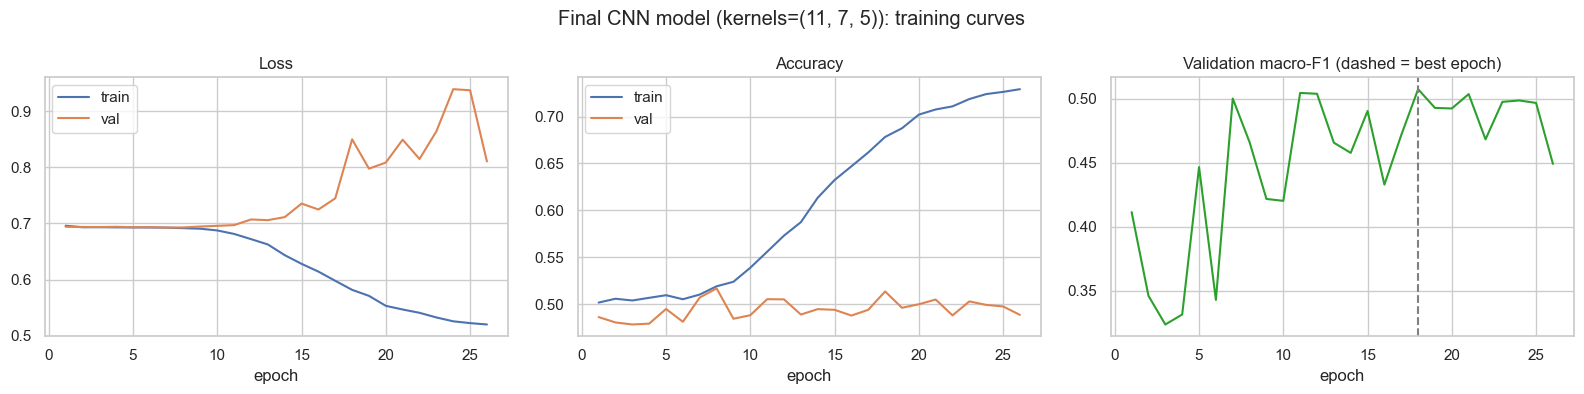

In [16]:
# ## Combine the best override from each group (same logic as NeuralNetwork.py)
 
best_per_group = log.loc[log.groupby("group")["val_macro_f1"].idxmax()]
combined_ov = {}
for _, row in best_per_group.iterrows():
    if row["group"] == "baseline":
        continue
    if row["val_macro_f1"] >= baseline["val_f1"]:
        combined_ov.update({k: v for k, v in results[row["run"]]["cfg"].items()
                             if BASELINE.get(k) != v})
print("Combined overrides:", combined_ov)
 
results["combined"] = train_model(combined_ov)
print(f"combined -> val macro-F1 {results['combined']['val_f1']:.3f} | val acc {results['combined']['val_acc']:.3f}")
 
best_name = max(results, key=lambda n: results[n]["val_f1"])
final = results[best_name]
print(f"\nSelected final CNN model: '{best_name}' (val macro-F1 {final['val_f1']:.3f})")
print("Final configuration:", {k: final['cfg'][k] for k in BASELINE})
plot_history(final, f"Final CNN model ({best_name}): training curves", "cnn_final_curves.png")

In [17]:

 
# ## Reference baseline (majority-class dummy)
val_pred = predict_logits(final["model"], X_val).argmax(1).numpy()
 
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
 
 
def row(name, pred):
    return {"model": name,
            "val_accuracy": accuracy_score(y_val, pred),
            "val_macro_F1": f1_score(y_val, pred, average="macro", zero_division=0)}
 
 
pd.DataFrame([
    row("Majority-class dummy", dummy.predict(np.zeros((len(y_val), 1)))),
    row(f"CNN ({best_name})", val_pred),
]).round(3)

,model,val_accuracy,val_macro_F1
0,Majority-class dummy,0.522,0.343
1,"CNN (kernels=(11, 7, 5))",0.513,0.508


In [18]:
 ## Final evaluation on the held-out test set
#
# IMPORTANT: val/test sequences were NOT sliding-window-chopped during
# EDA augmentation (only train was), so plenty of them are longer than
# MAX_LEN=200. Feeding them through build_onehot() directly would
# silently truncate anything past the first 200bp. windowed_predict_cnn()
# applies the same fix NeuralNetwork.py uses for the k-mer/MLP model:
# slice long sequences into 200bp windows, predict each, and average the
# softmax probabilities back to one prediction per original sequence.
 
WINDOW, STRIDE = 200, 50  # matches EDA's WINDOW_SIZE / WINDOW_STRIDE exactly
 
 
@torch.no_grad()
def windowed_predict_cnn(model, df, window=WINDOW, stride=STRIDE):
    seqs, owner = [], []
    for i, s in enumerate(df["sequence"]):
        s = str(s)
        if len(s) <= window:
            seqs.append(s); owner.append(i)
        else:
            for st in range(0, len(s) - window + 1, stride):
                seqs.append(s[st:st + window]); owner.append(i)
    X = torch.tensor(build_onehot(seqs, window))
    probs = F.softmax(predict_logits(model, X), dim=1).numpy()
    owner = np.array(owner)
    agg = np.vstack([probs[owner == i].mean(axis=0) for i in range(len(df))])
    return agg.argmax(1), agg
 
 
y_pred, test_probs = windowed_predict_cnn(final["model"], test_df)
print(classification_report(y_test, y_pred, target_names=classes, digits=3, zero_division=0))
 
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
per_class = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=classes).round(3)
per_class.to_csv("test_per_class_metrics_cnn.csv")
per_class

                 precision    recall  f1-score   support

   Homo sapiens      0.488     0.086     0.146      2647
Pan troglodytes      0.525     0.918     0.668      2912

       accuracy                          0.522      5559
      macro avg      0.507     0.502     0.407      5559
   weighted avg      0.507     0.522     0.419      5559



,precision,recall,f1,support
Homo sapiens,0.488,0.086,0.146,2647
Pan troglodytes,0.525,0.918,0.668,2912


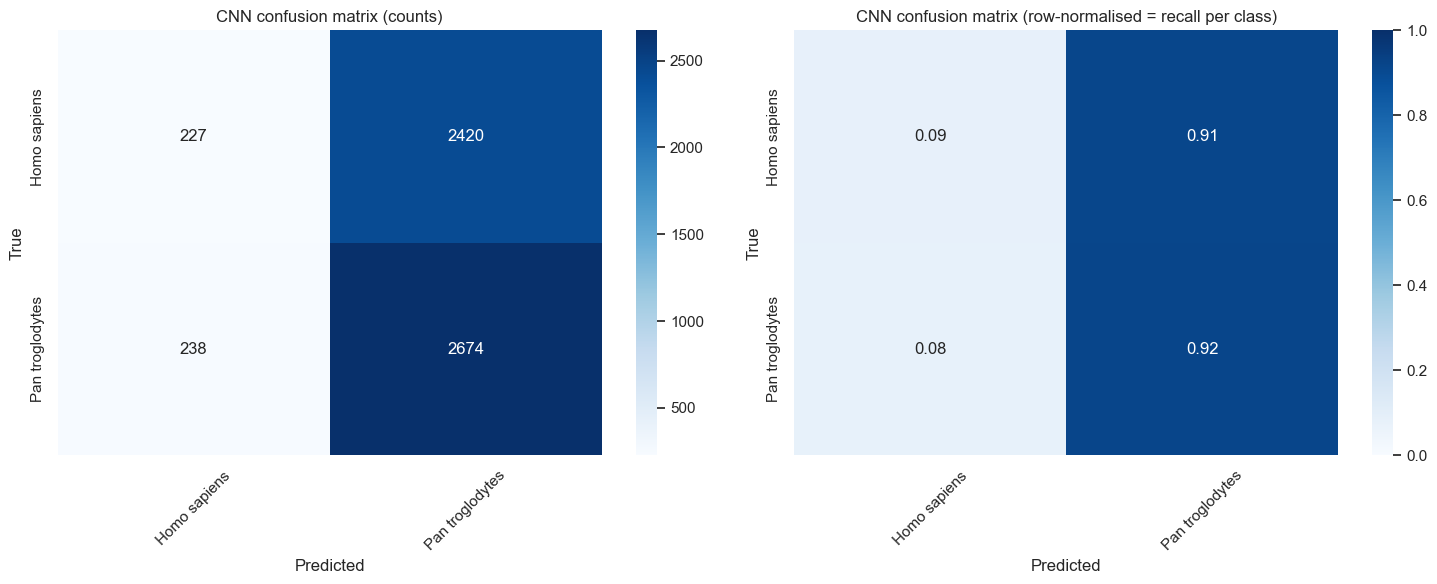

,true,predicted_as,count,share_of_true_class
0,Homo sapiens,Pan troglodytes,2420,0.914
1,Pan troglodytes,Homo sapiens,238,0.082


In [19]:
### Confusion matrices
 
cm = confusion_matrix(y_test, y_pred, labels=range(num_classes))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
 
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set_title("CNN confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set_title("CNN confusion matrix (row-normalised = recall per class)")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cnn_confusion_matrix.png"), dpi=150); plt.show()
 
# ### Error analysis
 
pairs = [(classes[i], classes[j], int(cm[i, j]), cm[i, j] / cm[i].sum())
         for i in range(num_classes) for j in range(num_classes) if i != j and cm[i, j] > 0]
errors = (pd.DataFrame(pairs, columns=["true", "predicted_as", "count", "share_of_true_class"])
          .sort_values("count", ascending=False).reset_index(drop=True))
errors.head(8).round(3)
 

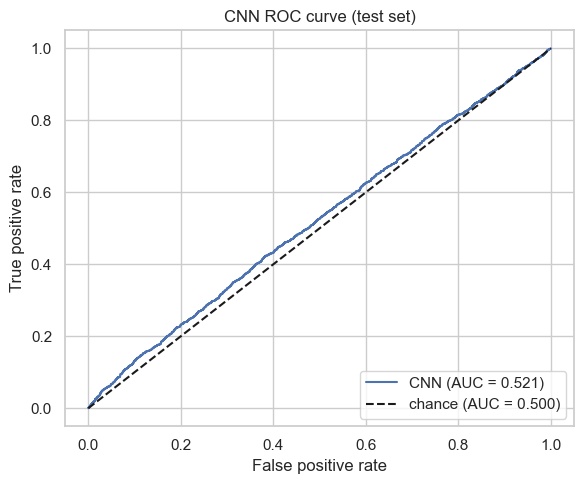

CNN ROC-AUC: 0.521


In [20]:
from sklearn.metrics import roc_auc_score, roc_curve

assert num_classes == 2, "This binary version expects human vs chimp only"
pos = label_map["Pan troglodytes"]
y_true_bin = (y_test == pos).astype(int)
y_score = test_probs[:, pos]                               # window-averaged P(chimp)

cnn_auc = roc_auc_score(y_true_bin, y_score)
fpr, tpr, _ = roc_curve(y_true_bin, y_score)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"CNN (AUC = {cnn_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="chance (AUC = 0.500)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("CNN ROC curve (test set)"); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "cnn_roc_curve.png"), dpi=150); plt.show()

print(f"CNN ROC-AUC: {cnn_auc:.3f}")
pd.DataFrame({"model": ["CNN"], "roc_auc": [round(cnn_auc, 3)]}).to_csv("test_roc_auc_cnn.csv", index=False)

In [21]:
 ### Specificity and False Negative Rate (per class, one-vs-rest)
#
# Precision/recall/F1 (already in per_class above) don't separately show
# how often the model MISSES a class entirely (false negatives) vs. how
# well it rejects everything that ISN'T that class (specificity). Both
# matter for the forensic framing: a false negative on Human means real
# human evidence could get wrongly ruled out before further testing.
 
spec_fnr = []
for i, c in enumerate(classes):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp                       # true class i, predicted something else
    fp = cm[:, i].sum() - tp                        # predicted class i, actually something else
    tn = cm.sum() - tp - fn - fp
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
    fnr = fn / (fn + tp) if (fn + tp) > 0 else float("nan")       # = 1 - recall
    spec_fnr.append({"class": c, "specificity": specificity, "false_negative_rate": fnr})
 
spec_fnr_df = pd.DataFrame(spec_fnr).round(3)
spec_fnr_df.to_csv("test_specificity_fnr_cnn.csv", index=False)
print(spec_fnr_df)
 
human_label = "Homo sapiens" if "Homo sapiens" in classes else None
if human_label:
    human_fnr = spec_fnr_df.loc[spec_fnr_df["class"] == human_label, "false_negative_rate"].iloc[0]
    print(f"\nHuman ({human_label}) false negative rate: {human_fnr:.1%} "
          f"-- the share of real human sequences the model mislabels as a non-human species.")
else:
    print("\nNote: adjust human_label above to match the exact class name used in your CSVs "
          "(e.g. 'Human' instead of 'Homo sapiens') to get this called out explicitly.")

             class  specificity  false_negative_rate
0     Homo sapiens        0.918                0.914
1  Pan troglodytes        0.086                0.082

Human (Homo sapiens) false negative rate: 91.4% -- the share of real human sequences the model mislabels as a non-human species.


In [22]:
# ## Test summary + save predictions (needed by compare_models.py)
#
# macro_F1 is the primary metric for this project, not weighted_F1 or
# accuracy: macro treats every class equally regardless of size, so a
# model that nails Human (54% of the data) but fails Cat (<1%) still
# scores poorly. weighted_F1 is included only for reference -- it would
# look artificially high on this dataset by letting the dominant Human
# class carry the score, which hides exactly the failure mode (poor
# performance on rare classes) this project needs to catch.
 
test_summary = pd.DataFrame({
    "model": ["CNN"],
    "accuracy": [accuracy_score(y_test, y_pred)],
    "macro_precision": [p.mean()],
    "macro_recall": [r.mean()],
    "macro_F1": [f1_score(y_test, y_pred, average="macro", zero_division=0)],
    "weighted_F1": [f1_score(y_test, y_pred, average="weighted", zero_division=0)],
}).round(3)
test_summary.to_csv("test_summary_cnn.csv", index=False)
test_summary
 
pd.DataFrame({"y_true": y_test, "y_pred": y_pred}).to_csv("test_predictions_cnn.csv", index=False)

In [23]:
 ## Save the model
 
torch.save({"state_dict": final["model"].state_dict(), "config": final["cfg"],
            "classes": classes, "max_len": MAX_LEN, "window": WINDOW, "stride": STRIDE},
           "dna_cnn_classifier.pt")
print("Saved dna_cnn_classifier.pt | figures in ./figures | "
      "logs: cnn_experiment_log.csv, test_per_class_metrics_cnn.csv, "
      "test_summary_cnn.csv, test_predictions_cnn.csv")
 

Saved dna_cnn_classifier.pt | figures in ./figures | logs: cnn_experiment_log.csv, test_per_class_metrics_cnn.csv, test_summary_cnn.csv, test_predictions_cnn.csv


# Reference-based human vs chimpanzee classifier (added section)

The neural networks above learn from short, gene-held-out sequences, where human and chimp are ~98-99% identical, so there is almost no species signal to learn.
This section instead compares a query to the **human and chimp versions of the same gene** and votes using only the k-mers where the two species differ ("diagnostic" k-mers).
Windows that contain no diagnostic k-mer are reported as *undecidable* rather than guessed.

In [24]:
from collections import Counter

K = 15                       # k-mer length (2*K = 30 bits, fits in a Python int)
SAMPLE_MOD = 16              # index only ~1/16 of k-mers to save memory
HUMAN, CHIMP = "Homo sapiens", "Pan troglodytes"
ENC = {"A": 0, "C": 1, "G": 2, "T": 3}
MASK = (1 << (2 * K)) - 1


def kmers(seq, k=K):
    """Set of 2-bit-encoded k-mers; windows containing non-ACGT are skipped."""
    out, code, valid = set(), 0, 0
    for ch in seq:
        v = ENC.get(ch)
        if v is None:
            code, valid = 0, 0
            continue
        code = ((code << 2) | v) & MASK
        valid += 1
        if valid >= k:
            out.add(code)
    return out


def build_references(df):
    """Return (diag, anchor, gene_names).

    diag[gene_id]   = (human_only_kmers, chimp_only_kmers)
    anchor[kmer]    = gene_id   (sampled k-mers; -1 if shared by several genes)
    """
    df = df[df["class"].isin([HUMAN, CHIMP])].copy()
    df["gene_key"] = df["gene"].astype(str).str.upper()

    per_gene = {}
    for gene, cls, seq in zip(df["gene_key"], df["class"], df["sequence"]):
        d = per_gene.setdefault(gene, {HUMAN: set(), CHIMP: set()})
        d[cls] |= kmers(str(seq).upper())          # union over transcript variants

    diag, anchor, gene_names = [], {}, []
    for gene, d in per_gene.items():
        h, c = d[HUMAN], d[CHIMP]
        if not h or not c:                          # need both species
            continue
        gid = len(gene_names)
        gene_names.append(gene)
        diag.append((h - c, c - h))
        for code in (h | c):
            if code % SAMPLE_MOD == 0:
                anchor[code] = gid if anchor.get(code, gid) == gid else -1
    return diag, anchor, gene_names


def classify(seq, diag, anchor, gene_id=None):
    """Return (pred, gene_id, n_human_only, n_chimp_only). pred is None if undecidable."""
    q = kmers(seq)
    if gene_id is None:
        votes = Counter(anchor[c] for c in q if c % SAMPLE_MOD == 0
                        and anchor.get(c, -1) >= 0)
        if not votes:
            return None, None, 0, 0
        gene_id = votes.most_common(1)[0][0]
    h_only, c_only = diag[gene_id]
    nh, nc = len(q & h_only), len(q & c_only)
    if nh == nc:
        return None, gene_id, nh, nc
    return (HUMAN if nh > nc else CHIMP), gene_id, nh, nc


def mutate(seq, rate, rng):
    """Random substitutions - simulates sequencing error / individual variation."""
    s = list(seq)
    for i in range(len(s)):
        if rng.random() < rate:
            s[i] = rng.choice([b for b in "ACGT" if b != s[i]])
    return "".join(s)


def evaluate(df, diag, anchor, gene_names, window=200, noise=0.003,
             n_queries=3000, seed=42):
    rng = random.Random(seed)
    name2id = {g: i for i, g in enumerate(gene_names)}
    d = df[df["class"].isin([HUMAN, CHIMP])].copy()
    d["gene_key"] = d["gene"].astype(str).str.upper()
    d = d[d["gene_key"].isin(name2id)].reset_index(drop=True)

    rows = d.sample(n=min(n_queries, len(d)), random_state=seed)
    res = dict(correct=0, wrong=0, undecidable=0, gene_ok=0, no_gene=0)
    for gene, cls, seq in zip(rows["gene_key"], rows["class"], rows["sequence"]):
        seq = str(seq).upper()
        if window and len(seq) > window:
            st = rng.randrange(0, len(seq) - window + 1)
            seq = seq[st:st + window]
        seq = mutate(seq, noise, rng)

        pred, gid, _, _ = classify(seq, diag, anchor)          # gene NOT given
        if gid is None:
            res["no_gene"] += 1
            continue
        res["gene_ok"] += int(gid == name2id[gene])
        if pred is None:
            res["undecidable"] += 1
        elif pred == cls:
            res["correct"] += 1
        else:
            res["wrong"] += 1

    n = len(rows)
    decided = res["correct"] + res["wrong"]
    print(f"queries                         : {n}  (window={window or 'full'}, noise={noise})")
    print(f"gene identified correctly       : {res['gene_ok'] / n:.1%}")
    print(f"undecidable (no diagnostic kmer): {res['undecidable'] / n:.1%}")
    print(f"accuracy on decidable queries   : {res['correct'] / max(decided, 1):.1%}")
    print(f"overall accuracy (ties=wrong)   : {res['correct'] / n:.1%}")


def make_demo(n_genes=300, length=1300, divergence=0.01, seed=0):
    rng = random.Random(seed)
    rows = []
    for g in range(n_genes):
        human = "".join(rng.choice("ACGT") for _ in range(length))
        chimp = mutate(human, divergence, rng)
        rows += [dict(sequence=human, **{"class": HUMAN}, gene=f"G{g}"),
                 dict(sequence=chimp, **{"class": CHIMP}, gene=f"G{g}")]
    return pd.DataFrame(rows)


In [25]:
# Build references from ALL sequences (both species, genes present in both)
all_df = pd.read_csv(os.path.join(DATA_DIR, "all_combined_dna.csv"))
diag, anchor, gene_names = build_references(all_df)
print(f"genes with both species: {len(gene_names)} | anchor k-mers: {len(anchor):,}\n")

# NOTE: queries come from the same sequences used as references, with simulated
# noise (default 0.3% substitutions). Treat results as an upper bound, not as
# performance on unseen individuals.
for window in (200, None):          # 200bp windows vs full-length sequences
    evaluate(all_df, diag, anchor, gene_names, window=window, noise=0.003)
    print()

genes with both species: 15667 | anchor k-mers: 1,520,767

queries                         : 3000  (window=200, noise=0.003)
gene identified correctly       : 97.4%
undecidable (no diagnostic kmer): 34.4%
accuracy on decidable queries   : 99.9%
overall accuracy (ties=wrong)   : 63.0%

queries                         : 3000  (window=full, noise=0.003)
gene identified correctly       : 100.0%
undecidable (no diagnostic kmer): 2.7%
accuracy on decidable queries   : 100.0%
overall accuracy (ties=wrong)   : 97.3%



In [26]:
# Train accuracy, measured with dropout off (the same idea as evaluate(train_loader))
tr_pred = predict_logits(final["model"], X_train).argmax(1).numpy()
print("Train accuracy:", round(accuracy_score(y_train, tr_pred), 3))

# Validation accuracy
print("Val accuracy  :", round(final["val_acc"], 3))

# Test accuracy (windowed, because many test sequences are longer than 200bp)
y_pred, _ = windowed_predict_cnn(final["model"], test_df)
print("Test accuracy :", round(accuracy_score(y_test, y_pred), 3))

Train accuracy: 0.76
Val accuracy  : 0.513
Test accuracy : 0.522


In [27]:
from difflib import SequenceMatcher

def _identity(query, ref):
    sm = SequenceMatcher(None, ref, query, autojunk=False)
    return sum(b.size for b in sm.get_matching_blocks()) / len(query)

def identify(seq, min_identity=0.97, verbose=True):
    seq = "".join(str(seq).split()).upper()
    log = print if verbose else (lambda *a, **k: None)
    log(f"Input: {len(seq)} bp")
    if len(seq) < 50:
        log("RESULT: UNKNOWN (too short)"); return "UNKNOWN"

    q = kmers(seq)
    anchors = [c for c in q if c % SAMPLE_MOD == 0]
    hits = sum(1 for c in anchors if c in anchor)
    log(f"Reference anchor k-mers found in this sequence: {hits} of {len(anchors)}")

    pred, gid, nh, nc = classify(seq, diag, anchor)
    if gid is None:
        log("RESULT: UNKNOWN (gene not in your human/chimp data)"); return "UNKNOWN"

    gene = gene_names[gid]
    rows = all_df[(all_df["gene"].astype(str).str.upper() == gene) &
                  (all_df["class"].isin([HUMAN, CHIMP]))]
    best = {HUMAN: 0.0, CHIMP: 0.0}
    for cls, s in zip(rows["class"], rows["sequence"]):
        best[cls] = max(best[cls], _identity(seq, str(s).upper()))
    top = max(best.values())
    log(f"Closest gene: {gene} | identity  human {best[HUMAN]:.1%}, chimp {best[CHIMP]:.1%}")
    if top < min_identity:
        log(f"RESULT: UNKNOWN (best match {top:.1%} < {min_identity:.0%})"); return "UNKNOWN"

    label = {HUMAN: "HUMAN", CHIMP: "CHIMP"}.get(pred, "CANNOT TELL")
    log(f"human-only k-mers: {nh}, chimp-only k-mers: {nc}")
    log("RESULT:", label)
    return label

In [28]:
identify("""         
ATGTTCTCTCCCTGGAAGATACCAATGTTTCTGTCTGTTCGTGAGG
ACTCCGTGCCCACCACGGCCTCTTTCAGCACCGACATGCTCAATGT
CACCTTGCAAGGGCCCACTCTTAACGGGACATTTGCCCAGAGCAAA
TGCCCCCAAGTGGAGTGGCTGGGCTGGCTCAACACCATCCAGCCCC
CCTTCCTCTGGGTGCTGTTCGTGCTGGCCACCCTAGAGAACATCTT

         """)

Input: 230 bp
Reference anchor k-mers found in this sequence: 10 of 10
Closest gene: BDKRB2 | identity  human 98.7%, chimp 100.0%
human-only k-mers: 0, chimp-only k-mers: 45
RESULT: CHIMP


'CHIMP'

In [ ]:
identify(
    """
ATGGCATTGGTTTTTCAATTCGGGCAGCCCGTCAGGGCTCAGCCTCTGCCAGGACTCTGCCACGGCAAGCTCATTCGGACAAACGCCTGTGATGTGTGCAACAGCACCGATCTTCCGGAAGTCGAGATCATTAGCCTGCTGGAGGAGCAGCTGCCCCATTATAAGTTAAGAGCCGACACCATCTACGGTTATGACCACGACGACTGGCTCCATACACCTCTCATTTCTCCAGATGCCAACATTGACCTCACAACCGAGCAAATTGAAGAGACGTTAAAATACTTCCTTTTATGTGCTGAAAGAGTTGGCCAGATGACTAAGACATATAATGACATAGATGCTGTCACTCGGCTTCTTGAGGAGAAAGAGCGGGATTTAGAATTGGCCGCTCGCATCGGCCAGTCGTTGTTGAAGAAGAACAAGACCCTAACCGAGAGGAACGAGCTGCTGGAGGAGCAGGTGGAACACATCAGGGAGGAGGTGTCTCAGCTCCGGCATGAGCTGTCCATGAAGGATGAGCTGCTTCAGTTCTACACCAGCGCTGCGGAGGAGAGTGAGCCCGAGTCCGTTTGCTCAACCCCGTTGAAGAGGAATGAGTCGTCCTCCTCAGTCCAGAATTACTTTCATTTGGATTCTCTTCAAAAGAAGCTGAAAGACCTTGAAGAGGAGAATGTTGTACTTCGATCCGAGGCCAGCCAGCTGAAGACAGAGACCATCACCTATGAGGAGAAGGAGCAGCAGCTGGTCAATGACTGCGTGAAGGAGCTGAGGGATGCCAATGTCCAGATTGCTAGTATCTCAGAGGAACTGGCCAAGAAGACGGAAGATGCTGCCCGCCAGCAAGAGGAGATCACACACCTGCTATCGCAAATAGTTGATTTGCAGAAAAAGGCAAAAGCTTGCGCAGTGGAAAATGAAGAACTTGTCCAGCATCTGGGGGCTGCTAAGGATGCCCAGCGGCAGCTCACAGCCGAGCTGCGTGAGCTGGAGGACAAGTACGCAGAGTGCATGGAGATGCTGCATGAGGCGCAGGAGGAGCTGAAGAACCTCCGGAACAAAACCATGCCCAATACCACGTCTCGGCGCTACCACTCACTGGGCCTGTTTCCCATGGATTCCTTGGCAGCAGAGATTGAGGGAACGATGCGCAAGGAGCTGCAGTTGGAAGAGGCCGAGTCTCCAGACATCACTCACCAGAAGCGTGTCTTTGAGACAGTAAGAAACATCAACCAGGTTGTCAAGCAGAGATCTCTGACCCCTTCTCCCATGAACATCCCCGGCTCCAACCAGTCCTCGGCCATGAACTCCCTCCTGTCCAGCTGCGTCAGCACCCCCCGGTCCAGCTTCTACGGCAGCGACATAGGCAACGTCGTCCTCGACAACAAGACCAACAGCATCATTCTGGAAACAGAGGCAGCCGACCTGGGAAACGATGAGCGGAGTAAGAAGCCGGGGACGCCGGGCACCCCAGGCTCCCACGACCTGGAGACGGCGCTGAGGCGGCTGTCCCTGCGCCGGGAGAACTACCTCTCGGAGAGGAGGTTCTTTGAGGAGGAGCAAGAGAGGAAGCTCCAGGAGCTGGCGGAGAAGGGCGAGCTGCGCAGCGGCTCCCTCACACCCACTGAGAGCATCATGTCCCTGGGCACGCACTCCCGCTTCTCCGAGTTCACCGGCTTCTCTGGCATGTCCTTCAGCAGCCGCTCCTACCTGCCTGAGAAGCTCCAGATCGTGAAGCCGCTGGAAGGTTCCGCCACACTTCACCACTGGCAGCAGTTGGCCCAACCTCACCTTGGGGGCATCCTGGACCCCCGGCCCGGTGTGGTCACCAAGGGCTTCCGGACGCTGGATGTTGACCTGGACGAAGTGTACTGCCTTAACGACTTTGAAGAAGATGACACAGGTGACCACATTTCTCTCCCACGCCTAGCTACCTCCACTCCAGTTCAGCACCCAGAGACCTCAGGTGAGAGGTCCCAAGCACGTGTGACTGTCTCAGGCAGCAGAAGTTACCCGAGCCGGCCTCAGGCTTCCCCAGAGGAGATGCAGGAGCCGCCAGCGGCCACGGAGGAGGAGGAGGAGGAGGAGGAGGAGGAGGGGTCTGCGCACCATCCTGGGAAGTGCATGTCTCAGACCAACTCCACCTTCACCTTCACCACCTGTCGCATCCTGCATCCTTCAGATGAGCTCACTCGGGTCACACCAAGCCTTAACTCAGCCCCAACTCCAGCTTGTGGCAGCACCAGCCACTTGAAATCCACGCCGGTGGCCACACCATGCACTCCACGGAGACTGAGCCTGGCTGAGTCCTTCACTAACACCCGTGAGTCCACGACCACCATGAGCACATCCCTGGGGCTCGTGTGGCTGTTGAAGGAGCGGGGCATTTCTGCTGCCGTGTACGACCCCCAGAGCTGGGACAGGGCCGGCCGGGGCTCCCTCCTGCACTCCTACACGCCCAAGATGGCTGTGATCCCCTCTACTCCGCCGAACTCGCCTATGCAGACACCCACATCCTCCCCACCCTCCTTTGAGTTCAAGTGCACGAGCCCTCCCTACGACAATTTCCTGGCTTCCAAGCCAGCCAGCTCCATCCTGAGGGAAGTGAGAGAAAAGAACGTCCGCAGCAGCGAGAGCCAGACCGACGTGTCCGTCTCCAACCTCAACCTCGTGGACAAAGTCAGGAGGTTTGGGGTGGCCAAAGTGGTGAACTCAGGGCGAGCCCATGTCCCCACCTTGACTGAGGAGCAGGGACCCCTCCTCTGTGGGCCCCCGGGGCCAGCACCAGCCCTTGTTCCCAGAGGCCTGGTACCTGAGGGCCTGCCCCTCAGATGCCCCACTGTCACCAGTGCCATCGGTGGGCTGCAGCTCAATAGTGGCATCCGGCGGAATCGCAGCTTCCCCACCATGGTGGGATCTAGCATGCAGATGAAAGCTCCTGTGACTCTCACCTCGGGCATCTTGATGGGTGCTAAGCTCTCCAAACAAACTAGCTTACGGTGA
"""
)

Input: 3000 bp
Reference anchor k-mers found in this sequence: 148 of 148
Closest gene: TRAK1 | identity  human 100.0%, chimp 95.0%
human-only k-mers: 301, chimp-only k-mers: 0
RESULT: HUMAN


'HUMAN'

In [30]:
identify("""
ATGTTCATTAATCGATGACTATTCTCAACCAACCATAAAGATATTGGTACCCTGTACCTA
TTATTTGGTGCCTGAGCAGGTATAGTAGGAACTGCTCTAAGCCTCCTAATCCGTGCTGAA
TTAGGCCAACCTGGCACTCTACTAGGAGATGATCAAATTTACAATGTAATCGTTACTGCT
CATGCATTCGTAATAATCTTCTTCATAGTAATACCTATCATAATTGGAGGATTCGGAAAC
""")

Input: 240 bp
Reference anchor k-mers found in this sequence: 2 of 19
Closest gene: COX1 | identity  human 77.1%, chimp 80.4%
RESULT: UNKNOWN (best match 80.4% < 97%)


'UNKNOWN'